# Delhi Air Quality Analysis (January 2023)

**Intermediate Data Science Internship Project**  
Dataset: `delhiaqi.csv`

## 1. Project objective
Explore the supplied Delhi pollutant time series to understand short-term patterns, pollutant relationships, and changes across the observed period. This notebook emphasizes reproducible exploratory data analysis (EDA), descriptive statistics, and visual communication.

> **Important scope note:** The supplied file contains pollutant measurements, not an official AQI column. It also does not document measurement units, monitoring-station coordinates, or multiple locations. Therefore, this project analyzes the provided pollutant values and does **not** calculate or claim official AQI categories, health-risk categories, or geographical effects.

## 2. Research questions
1. How do pollutant values vary during the observed period?
2. How do particulate matter (`pm2_5`, `pm10`) compare with gaseous pollutants in their distributions?
3. Are there time-of-day patterns in the observed measurements?
4. Which pollutant pairs move together in this dataset?
5. Which timestamps show the largest values, and what caveats apply when interpreting them?


In [ ]:
# Imports and reproducible plotting setup
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("delhiaqi.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titleweight"] = "bold"

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df.head()


,date,co,no,no2,o3,so2,pm2_5,pm10,nh3
0,2023-01-01 00:00:00,1655.58,1.66,39.41,5.90,17.88,169.29,194.64,5.83
1,2023-01-01 01:00:00,1869.20,6.82,42.16,1.99,22.17,182.84,211.08,7.66
2,2023-01-01 02:00:00,2510.07,27.72,43.87,0.02,30.04,220.25,260.68,11.40
3,2023-01-01 03:00:00,3150.94,55.43,44.55,0.85,35.76,252.90,304.12,13.55
4,2023-01-01 04:00:00,3471.37,68.84,45.24,5.45,39.10,266.36,322.80,14.19


## 3. Dataset overview and quality checks

In [ ]:
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Time range: {df['date'].min()} to {df['date'].max()}")
print(f"Unique timestamps: {df['date'].nunique():,}")
display(df.dtypes.to_frame("dtype"))
display(df.describe(include="all").T)


Rows: 561
Columns: 9
Time range: 2023-01-01 00:00:00 to 2023-01-24 08:00:00
Unique timestamps: 561


,dtype
date,datetime64[ns]
co,float64
no,float64
no2,float64
o3,float64
so2,float64
pm2_5,float64
pm10,float64
nh3,float64


,count,mean,min,25%,50%,75%,max,std
date,561,2023-01-12 16:00:00,2023-01-01 00:00:00,2023-01-06 20:00:00,2023-01-12 16:00:00,2023-01-18 12:00:00,2023-01-24 08:00:00,NaN
co,561.0,3814.94221,654.22,1708.98,2590.18,4432.68,16876.22,3227.744681
no,561.0,51.181979,0.0,3.38,13.3,59.01,425.58,83.904476
no2,561.0,75.292496,13.37,44.55,63.75,97.33,263.21,42.473791
o3,561.0,30.141943,0.0,0.07,11.8,47.21,164.51,39.979405
so2,561.0,64.655936,5.25,28.13,47.21,77.25,511.17,61.07308
pm2_5,561.0,358.256364,60.1,204.45,301.17,416.65,1310.2,227.359117
pm10,561.0,420.988414,69.08,240.9,340.9,482.57,1499.27,271.287026
nh3,561.0,26.425062,0.63,8.23,14.82,26.35,267.51,36.563094


In [ ]:
# Data-quality checks
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
    "dtype": df.dtypes.astype(str)
})
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate timestamps:", int(df["date"].duplicated().sum()))
display(quality)

# Sort chronologically and create time-derived fields for analysis.
df = df.sort_values("date").reset_index(drop=True)
pollutants = [c for c in df.columns if c != "date"]
df["hour"] = df["date"].dt.hour
df["day"] = df["date"].dt.date
df["date_only"] = df["date"].dt.floor("D")
print("Time interval counts:")
display(df["date"].diff().value_counts().head(10).rename_axis("interval").to_frame("count"))


Exact duplicate rows: 0
Duplicate timestamps: 0


,missing_values,unique_values,dtype
date,0,561,datetime64[ns]
co,0,224,float64
no,0,346,float64
no2,0,198,float64
o3,0,283,float64
so2,0,231,float64
pm2_5,0,557,float64
pm10,0,556,float64
nh3,0,269,float64


Time interval counts:


,count
interval,
0 days 01:00:00,560


### Data preparation notes
- The timestamp is parsed as a datetime and rows are sorted chronologically.
- The supplied data has 561 hourly observations from **1 January 2023 00:00** through **24 January 2023 08:00**.
- The file has eight pollutant columns: `co`, `no`, `no2`, `o3`, `so2`, `pm2_5`, `pm10`, and `nh3`.
- Missing values and duplicate rows/timestamps are checked before analysis.
- No values are imputed, and no outliers are automatically deleted. Extreme values may be meaningful events or data-quality issues; the dataset alone cannot determine which.
- Units and measurement provenance are not included in the CSV, so values are interpreted in the dataset's recorded scale only.


## 4. Research question 1 — How do pollutant levels change over time?

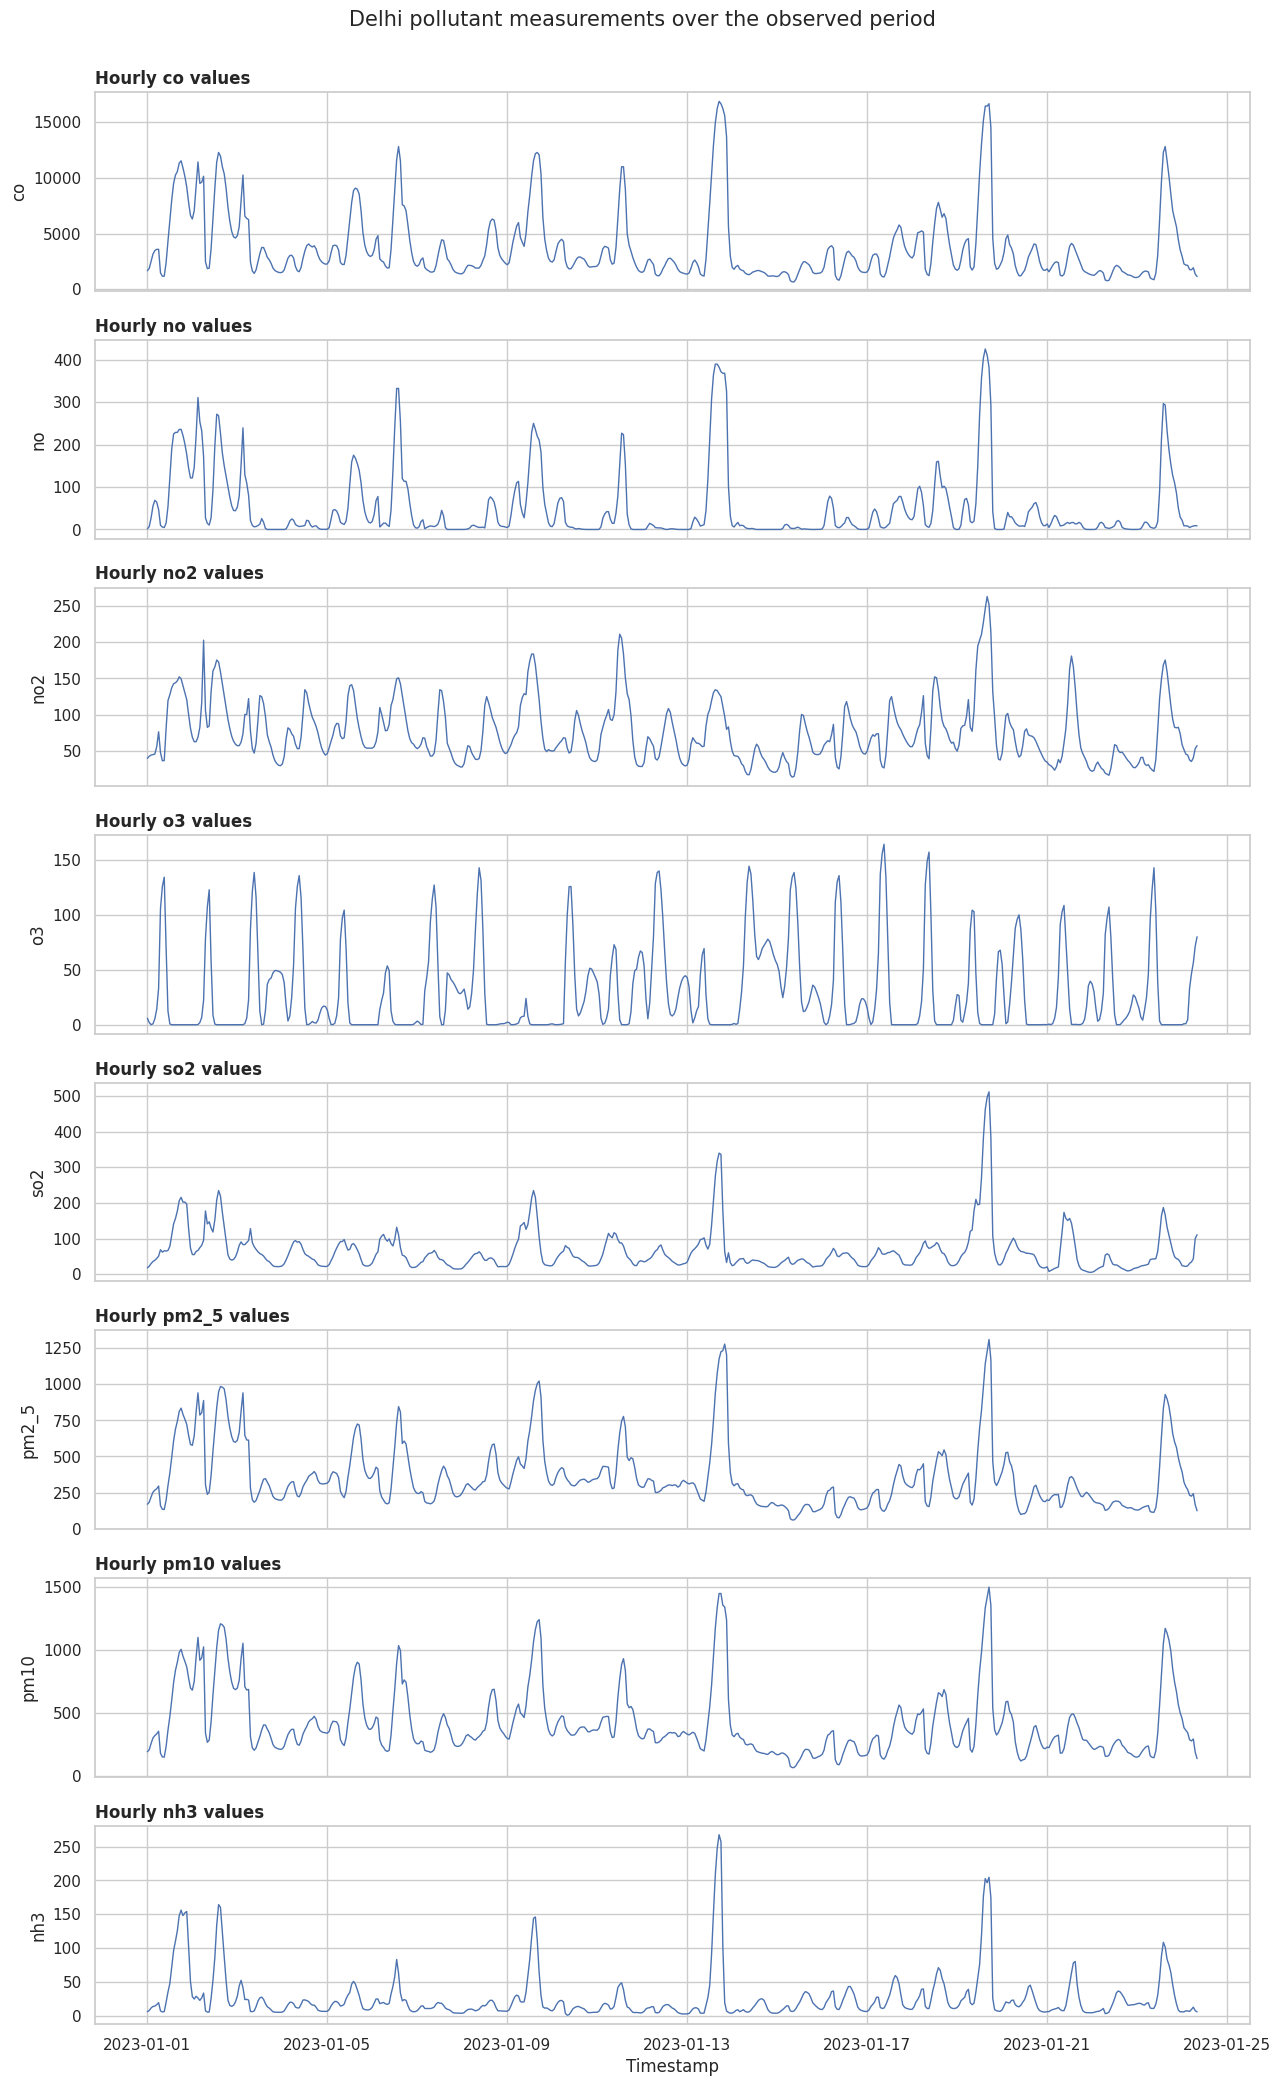

In [ ]:
# Hourly time series, one panel per pollutant
fig, axes = plt.subplots(len(pollutants), 1, figsize=(13, 2.6 * len(pollutants)), sharex=True)
for ax, col in zip(axes, pollutants):
    ax.plot(df["date"], df[col], linewidth=1)
    ax.set_ylabel(col)
    ax.set_title(f"Hourly {col} values", loc="left")
axes[-1].set_xlabel("Timestamp")
fig.suptitle("Delhi pollutant measurements over the observed period", y=1.002, fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hourly_pollutant_trends.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Research question 2 — What do the pollutant distributions look like?

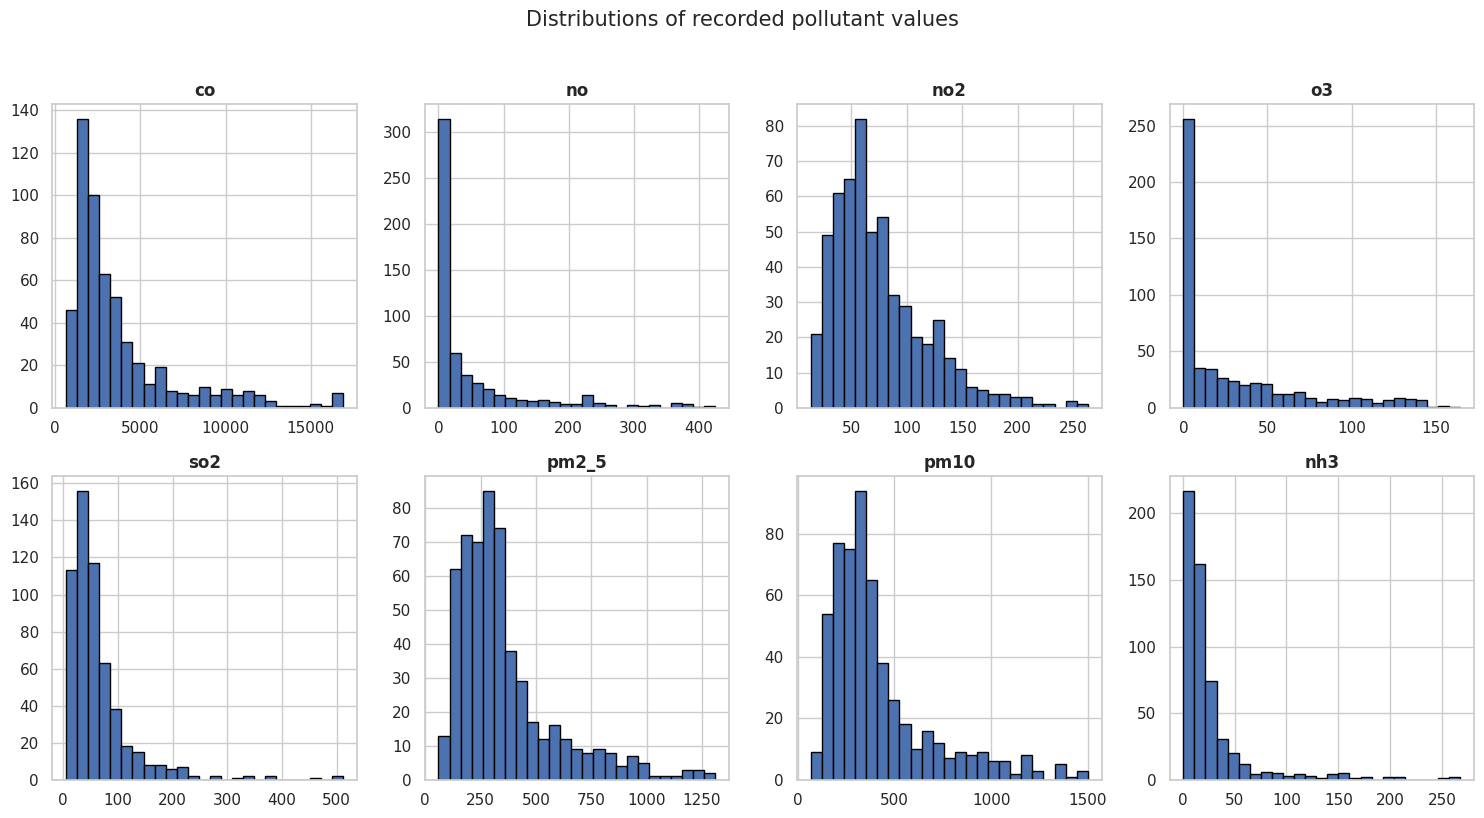

,mean,median,std,min,max,skew
co,3814.942,2590.18,3227.745,654.22,16876.22,1.944
pm10,420.988,340.90,271.287,69.08,1499.27,1.673
pm2_5,358.256,301.17,227.359,60.10,1310.20,1.681
no2,75.292,63.75,42.474,13.37,263.21,1.281
so2,64.656,47.21,61.073,5.25,511.17,3.377
no,51.182,13.30,83.904,0.00,425.58,2.345
o3,30.142,11.80,39.979,0.00,164.51,1.410
nh3,26.425,14.82,36.563,0.63,267.51,3.484


In [ ]:
# Separate panels are used because pollutant columns have different numeric scales.
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, col in zip(axes.flat, pollutants):
    ax.hist(df[col].dropna(), bins=25, edgecolor="black")
    ax.set_title(col)
fig.suptitle("Distributions of recorded pollutant values", y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pollutant_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

summary = df[pollutants].agg(["mean", "median", "std", "min", "max", "skew"]).T
summary = summary.sort_values("mean", ascending=False)
display(summary.round(3))


## 6. Research question 3 — Is there a time-of-day pattern?

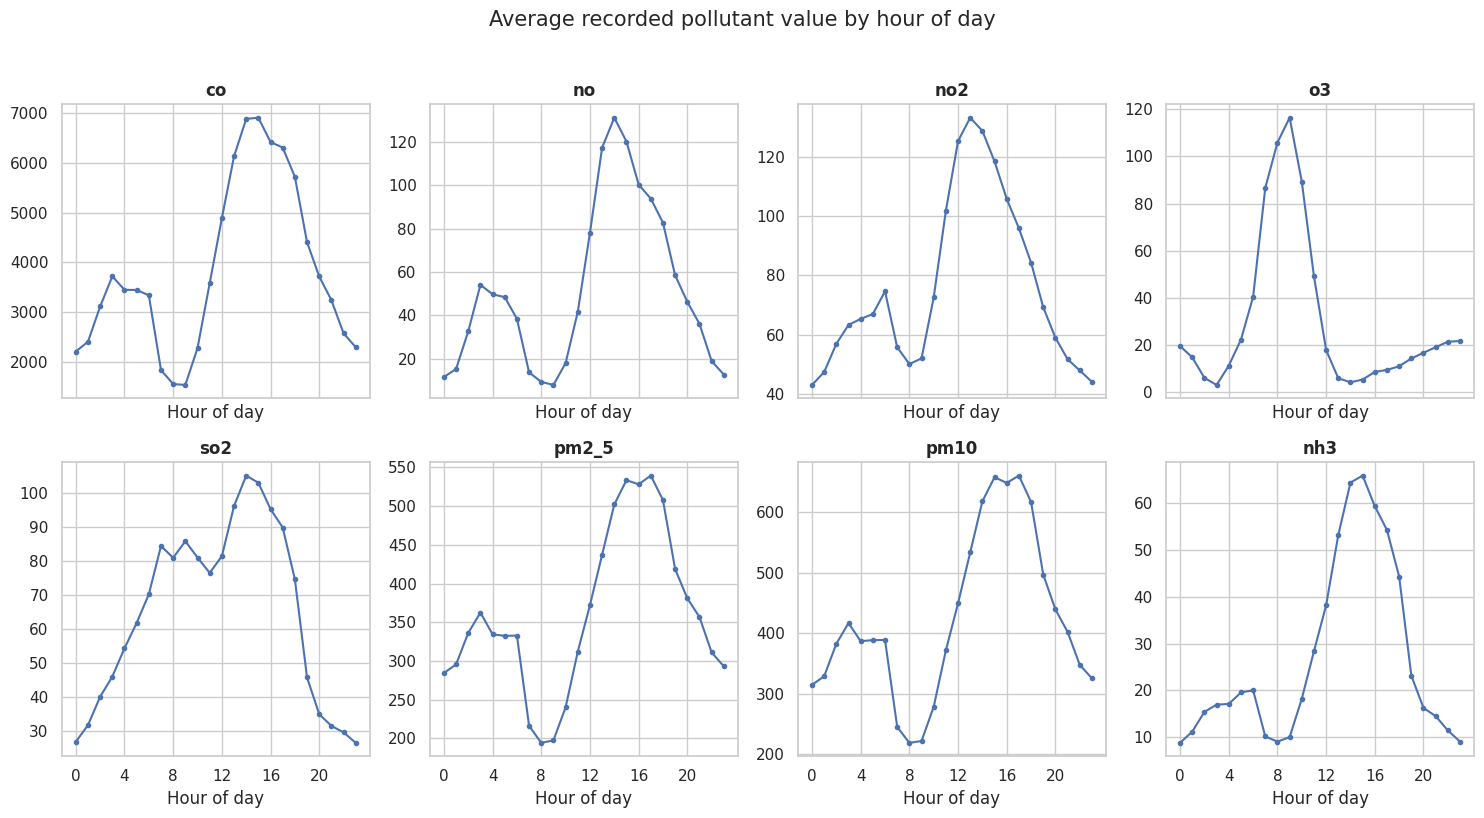

,co,no,no2,o3,so2,pm2_5,pm10,nh3
hour,,,,,,,,
0,2207.44,11.63,43.07,19.62,26.86,284.57,314.64,8.77
1,2405.48,15.33,47.42,14.84,31.79,295.63,328.78,11.18
2,3114.22,32.67,56.95,6.16,40.12,336.28,382.43,15.40
3,3719.49,54.08,63.30,3.15,46.08,362.63,416.65,16.95
4,3448.57,49.72,65.36,11.33,54.40,334.48,386.67,17.10
5,3445.23,48.41,66.97,22.32,61.87,332.57,388.53,19.56
6,3339.53,38.40,74.63,40.49,70.32,332.87,388.69,20.03
7,1833.88,13.73,55.78,86.65,84.54,216.31,245.28,10.15
8,1554.61,9.42,50.14,105.81,81.04,194.31,218.86,9.03


In [ ]:
hourly_profile = df.groupby("hour")[pollutants].mean()
fig, axes = plt.subplots(2, 4, figsize=(15, 8), sharex=True)
for ax, col in zip(axes.flat, pollutants):
    ax.plot(hourly_profile.index, hourly_profile[col], marker="o", markersize=3)
    ax.set_title(col)
    ax.set_xlabel("Hour of day")
    ax.set_xticks(range(0, 24, 4))
fig.suptitle("Average recorded pollutant value by hour of day", y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hourly_profiles.png", dpi=160, bbox_inches="tight")
plt.show()

display(hourly_profile.round(2))


## 7. Research question 4 — Which pollutants move together?

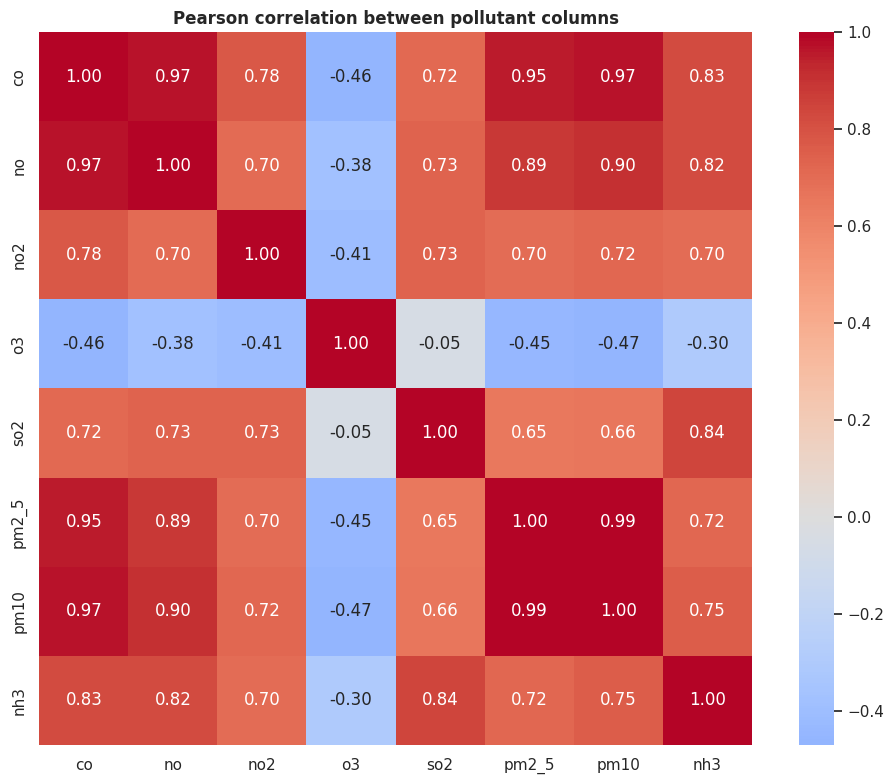

pearson_r  absolute_r
pm2_5 pm10       0.994       0.994
co    no         0.970       0.970
      pm10       0.967       0.967
      pm2_5      0.953       0.953
no    pm10       0.903       0.903
      pm2_5      0.889       0.889
so2   nh3        0.844       0.844
co    nh3        0.826       0.826
no    nh3        0.824       0.824
co    no2        0.776       0.776

In [ ]:
corr = df[pollutants].corr(method="pearson")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Pearson correlation between pollutant columns")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pollutant_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

# Rank pairs by absolute correlation, excluding self-correlations and duplicate pairs.
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().rename("pearson_r").to_frame()
pairs["absolute_r"] = pairs["pearson_r"].abs()
display(pairs.sort_values("absolute_r", ascending=False).head(10).round(3))


## 8. Research question 5 — When are the largest readings observed?

,pollutant,peak_value,timestamp
0,co,16876.22,2023-01-13 17:00:00
6,pm10,1499.27,2023-01-19 17:00:00
5,pm2_5,1310.20,2023-01-19 17:00:00
4,so2,511.17,2023-01-19 17:00:00
1,no,425.58,2023-01-19 15:00:00
7,nh3,267.51,2023-01-13 17:00:00
2,no2,263.21,2023-01-19 16:00:00
3,o3,164.51,2023-01-17 09:00:00


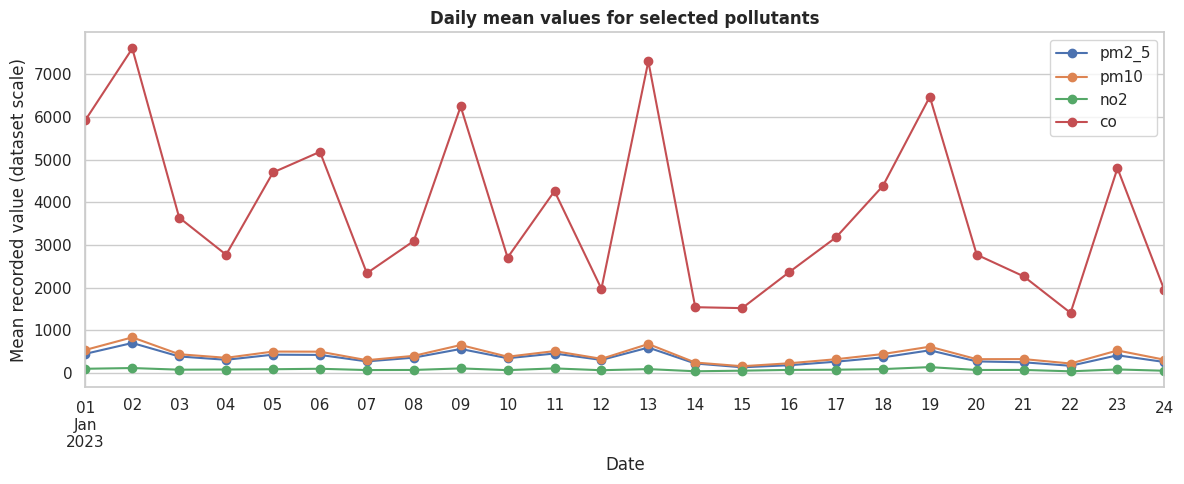

In [ ]:
# Highest timestamps for each pollutant. This is descriptive, not an attribution of cause.
peak_rows = []
for col in pollutants:
    idx = df[col].idxmax()
    peak_rows.append({
        "pollutant": col,
        "peak_value": df.loc[idx, col],
        "timestamp": df.loc[idx, "date"]
    })
peaks = pd.DataFrame(peak_rows).sort_values("peak_value", ascending=False)
display(peaks)

# Daily mean trends for selected pollutants
daily = df.set_index("date").resample("D")[["pm2_5", "pm10", "no2", "co"]].mean()
ax = daily.plot(marker="o", figsize=(12, 5))
ax.set_title("Daily mean values for selected pollutants")
ax.set_xlabel("Date")
ax.set_ylabel("Mean recorded value (dataset scale)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "daily_means_selected_pollutants.png", dpi=160, bbox_inches="tight")
plt.show()


## 9. Findings and interpretation

Use the output tables and charts above to discuss:
- **Time variation:** the hourly series show whether pollutant values are stable or include sharp short-lived peaks.
- **Distribution and extremes:** compare means with medians and inspect skewness. A large gap can indicate a right-skewed distribution, but it does not by itself identify the cause.
- **Daily cycle:** the hour-of-day profiles summarize the average recorded value for each hour across the available dates. They are descriptive and can be affected by the short observation window.
- **Relationships:** Pearson correlation describes linear co-movement, not causation. Shared weather conditions, emissions, temporal patterns, or measurement factors could influence correlations, but these causes cannot be tested with this file alone.
- **Peak readings:** the peak table identifies the timestamp of each column's maximum. Peaks should be validated against original source metadata before policy or health conclusions are drawn.

### AQI and environmental context
The task brief asks for an in-depth analysis of AQI in Delhi. The supplied CSV contains pollutant columns but no `AQI` field, and it does not specify the units needed to reliably compare values with official pollutant standards. This notebook therefore treats the data as pollutant measurements and does not invent an AQI score. To extend this work into an official AQI study, obtain the source/API documentation, units, monitoring station metadata, and a documented AQI calculation standard.

### Seasonal and geographical limitations
This dataset covers only 1–24 January 2023, so it cannot support comparisons across seasons or years. It also has no station, latitude/longitude, neighborhood, wind, temperature, or other meteorological columns; geographical effects and their causes cannot be assessed from this dataset alone.


## 10. Conclusion and next steps

This project establishes a reproducible baseline for inspecting the supplied Delhi pollutant time series using data-quality checks, descriptive statistics, time-series plots, distribution plots, hourly profiles, and correlation analysis.

Recommended next steps:
1. Add documented units and source metadata, including station names and coordinates.
2. Add a longer period covering multiple seasons and years.
3. Join weather and meteorological data to explore possible explanatory factors.
4. If the intended outcome is official AQI, obtain a documented AQI series or calculate it only from verified pollutant units and the applicable official method.
5. Compare multiple Delhi monitoring stations to investigate geographical differences.

## Reproducibility
Run the notebook from the project root. It reads `delhiaqi.csv` and writes charts to `outputs/`. See `README.md` for setup instructions.
